# Reviewer response: experimental and diffusion replicate variation

Select **5 unique seeding configurations**, without replacement (seed 42), with two experimental replicates and two diffusion samples. Use the **same configurations and order** for both sources. Each source has a five-row panel: **replicate 1 | replicate 2 | SSIM | absolute difference in mean terminal width | absolute difference in tip count | absolute difference in skeleton length**. Panels contain only images and numerical values; column meanings and row identifiers are printed separately.

This is a reproducible example panel, not an estimate over the complete test set. The sampling unit is a configuration; terminals are not independent biological replicates.

## Definitions and sources

- [Current analysis plan](Markdown%20files/morphometric_analysis_current_plan.md), [concise methods](Markdown%20files/morphometric_methods_concise.md), [detailed methods](Markdown%20files/morphometric_methods_draft.md), and [reviewer requests](Markdown%20files/reviewer_analysis_todo_summary.md) define the measurements and within-configuration comparison.
- [Variation notebook](morphometric_variation_analysis.ipynb) and [image-comparison notebook](morphometric_expsimdiff_display_SuppFig15A.ipynb) supply the preprocessing and terminal-width method. The [historical skeleton plan](Markdown%20files/skeletonization_morphometric_plan.md) provides background; current definitions take precedence.
- [Supplementary Figure 1](../../seed_to_sim1_sim2_deterministic/SSIM_ExpandSim_SuppFig2.ipynb) and its `utils/display.py::display_images_with_ssim_3rows` supply the large-number layout and grayscale SSIM convention (PIL luminance, normalized to [0, 1], `data_range=1`). SSIM is on full preprocessed color images converted to grayscale, **not binary masks**; no extra alignment is fitted.
- [batch_infer.py](batch_infer.py) generates `configuration_1.png` and `configuration_2.png` in one batch from one simulation per original-test configuration. For fixed-seed tests, use `Fixed_N_1_1.png` and `Fixed_N_1_2.png`: two stochastic samples from the **same input stem**, rather than mixing inputs associated with different experimental replicates.
- [Preprocessing](cldm/preprocess.py) crops experimental images by 25 pixels on each side and resizes to 256×256; generated images need no crop. Near-white generated pixels are removed only for segmentation, following the existing notebooks. Experimental RGB images use `preprocess_experimental_backgroundwhite` for the cropped, resized white-background display and grayscale SSIM, matching the Supplementary Figure 1 display convention. Experimental masks still use `preprocess_experimental_backgroundblack_blackandwhite` so background replacement cannot become colony foreground. Diffusion uses the original RGB image for display/SSIM and the no-cropping function for segmentation.
- [Skeleton implementation](cldm/morpho_features.py): deterministic medial axis, broad-core reconstruction and spur pruning with the current defaults. Tips have one 8-connected neighbor. Skeleton length sums Skan path lengths, including loops and diagonal distances. Terminal width is twice the prepared-mask distance transform at the first path pixel ≥5 pixels inward from a tip; shorter paths are omitted from width only. Mean width weights eligible terminals equally within each plate.

Differences are **absolute**: `|replicate 2 − replicate 1|`. Signed differences and individual replicate measurements are also exported. Width and skeleton length are converted using the existing variation-notebook scale, `10 / 25.92` mm per pixel (approximately 0.3858 mm/px). Pixel measurements are retained in the exported tables for traceability. Missing widths are NaN (shown as “NA”), never zero.

In [1]:
# FIGURE TEXT SIZE: change this value and rerun the notebook.
NUMBER_FONTSIZE = 40

from pathlib import Path
import sys
import json
from dataclasses import asdict
import platform
import importlib.metadata

# Run from this folder, the repository root, or the workspace root.
_candidates = [Path.cwd(), Path.cwd() / 'sim_to_exp_diffusion/controlnet_essential',
               Path.cwd() / 'Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/controlnet_essential']
PROJECT_DIR = next((p.resolve() for p in _candidates if (p / 'cldm/morpho_features.py').is_file()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError('Run from controlnet_essential, the repository root, or the workspace root.')
sys.path.insert(0, str(PROJECT_DIR))

import cv2
import matplotlib
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
from matplotlib import font_manager as fm
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display
from scipy.ndimage import distance_transform_edt
from skimage.metrics import structural_similarity
from cldm.config import (EXP_FOLDER_TEST, MAIN_FOLDER, EXP_FOLDER_TEST_FIXED,
                         DIFFUSION_FOLDER_TEST_FIXED, FPATH)
from cldm.preprocess import (preprocess_experimental_backgroundwhite,
    preprocess_experimental_backgroundblack_blackandwhite,
    preprocess_experimental_backgroundblack_blackandwhite_nocropping)
from cldm.morpho_features import (SkeletonConfig, skeletonize_colony,
                                 summarize_skeleton, endpoint_pixel_map)

if Path(FPATH).is_file():
    fm.fontManager.addfont(str(FPATH))
    plt.rcParams['font.family'] = fm.FontProperties(fname=str(FPATH)).get_name()
else:
    plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams.update({'pdf.fonttype': 42, 'ps.fonttype': 42})

In [2]:
# Editable analysis and display parameters.
SAMPLE_COUNT = 5
RANDOM_SEED = 42
INCLUDE_FIXED_TEST = True  # False restricts selection to the original 96-image cohort.
EXPERIMENT_DIR = Path(EXP_FOLDER_TEST)
DIFFUSION_DIR = Path(MAIN_FOLDER)
FIXED_EXPERIMENT_DIR = Path(EXP_FOLDER_TEST_FIXED)
FIXED_DIFFUSION_DIR = Path(DIFFUSION_FOLDER_TEST_FIXED)
SKELETON_CONFIG = SkeletonConfig()  # Same settings as the current comparison notebooks.
TERMINAL_INSET_PX = 5.0
MM_PER_PIXEL = 10 / 25.92  # Same calibration as morphometric_variation_analysis.ipynb.
OUTPUT_DIR = PROJECT_DIR / 'replicate_variation_analysis'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Audit eligible replicate pairs before sampling

Only complete `_1`/`_2` experimental pairs with both required generated samples are eligible. The optional fixed-seed cohort is included by default, consistent with the current 132-image morphology analysis. Incomplete configurations are listed and excluded **before** sampling. Missing folders raise an error rather than silently changing the cohort. No conditions are selected based on metric values.

In [3]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
def index_images(folder, extensions):
    if not folder.is_dir():
        raise FileNotFoundError(f'Missing configured test folder: {folder}')
    result = {}
    for path in sorted(folder.iterdir()):
        if path.is_file() and path.suffix.lower() in extensions:
            if path.stem in result:
                raise ValueError(f'Duplicate image stem in {folder}: {path.stem}')
            result[path.stem] = path
    return result


def configuration_pairs(experiment_dir, diffusion_dir, cohort):
    experiments = index_images(experiment_dir, {'.tif', '.tiff', '.png'})
    generated = index_images(diffusion_dir, {'.png'})
    configs = sorted({stem.rsplit('_', 1)[0] for stem in experiments
                      if stem.rsplit('_', 1)[-1] in {'1', '2'}})
    rows = []
    for config_id in configs:
        exp_stems = [f'{config_id}_1', f'{config_id}_2']
        diff_stems = ([f'{config_id}_1_1', f'{config_id}_1_2']
                      if cohort == 'fixed' else exp_stems)
        missing = ([s for s in exp_stems if s not in experiments]
                   + [s for s in diff_stems if s not in generated])
        rows.append({'configuration_id': config_id, 'cohort': cohort,
                     'eligible': not missing, 'missing_stems': ', '.join(missing),
                     'experiment_1': experiments.get(exp_stems[0]),
                     'experiment_2': experiments.get(exp_stems[1]),
                     'diffusion_1': generated.get(diff_stems[0]),
                     'diffusion_2': generated.get(diff_stems[1])})
    if not rows:
        raise ValueError(f'No replicate configuration IDs found in {experiment_dir}')
    return pd.DataFrame(rows)

inventory_parts = [configuration_pairs(EXPERIMENT_DIR, DIFFUSION_DIR, 'original')]
if INCLUDE_FIXED_TEST:
    inventory_parts.append(configuration_pairs(FIXED_EXPERIMENT_DIR, FIXED_DIFFUSION_DIR, 'fixed'))
inventory_df = pd.concat(inventory_parts, ignore_index=True)
if inventory_df['configuration_id'].duplicated().any():
    raise ValueError('Configuration IDs overlap across cohorts; check test folders.')
eligible_df = inventory_df.loc[inventory_df['eligible']].sort_values('configuration_id').reset_index(drop=True)
print(f'{len(eligible_df)} eligible configurations; {(~inventory_df.eligible).sum()} incomplete configurations')
display(inventory_df.groupby('cohort')['eligible'].agg(['count', 'sum']))
display(inventory_df.loc[~inventory_df.eligible, ['configuration_id', 'cohort', 'missing_stems']])
if len(eligible_df) < SAMPLE_COUNT:
    raise ValueError(f'Need {SAMPLE_COUNT} complete configurations, found {len(eligible_df)}.')
selected_indices = np.random.default_rng(RANDOM_SEED).choice(len(eligible_df), SAMPLE_COUNT, replace=False)
selected_df = eligible_df.iloc[selected_indices].reset_index(drop=True)
selected_df.insert(0, 'panel_row', np.arange(1, SAMPLE_COUNT + 1))
inventory_df.to_csv(_figure_source_path(OUTPUT_DIR / 'replicate_inventory.csv'), index=False)
selected_df.to_csv(_figure_source_path(OUTPUT_DIR / 'selected_configurations.csv'), index=False)
display(selected_df)

65 eligible configurations; 2 incomplete configurations


,count,sum
cohort,,
fixed,19,17
original,48,48


,configuration_id,cohort,missing_stems
51,Fixed_12,fixed,Fixed_12_2
54,Fixed_15,fixed,Fixed_15_2


,panel_row,configuration_id,cohort,eligible,missing_stems,experiment_1,experiment_2,diffusion_1,diffusion_2
0,1,251,original,True,,/hpc/group/youlab/ks723/storage/Exp_images/Fin...,/hpc/group/youlab/ks723/storage/Exp_images/Fin...,/hpc/dctrl/ks723/Physics_constrained_DL_patter...,/hpc/dctrl/ks723/Physics_constrained_DL_patter...
1,2,231,original,True,,/hpc/group/youlab/ks723/storage/Exp_images/Fin...,/hpc/group/youlab/ks723/storage/Exp_images/Fin...,/hpc/dctrl/ks723/Physics_constrained_DL_patter...,/hpc/dctrl/ks723/Physics_constrained_DL_patter...
2,3,245,original,True,,/hpc/group/youlab/ks723/storage/Exp_images/Fin...,/hpc/group/youlab/ks723/storage/Exp_images/Fin...,/hpc/dctrl/ks723/Physics_constrained_DL_patter...,/hpc/dctrl/ks723/Physics_constrained_DL_patter...
3,4,201,original,True,,/hpc/group/youlab/ks723/storage/Exp_images/Fin...,/hpc/group/youlab/ks723/storage/Exp_images/Fin...,/hpc/dctrl/ks723/Physics_constrained_DL_patter...,/hpc/dctrl/ks723/Physics_constrained_DL_patter...
4,5,Fixed_9,fixed,True,,/hpc/group/youlab/ks723/storage/Exp_images/Fin...,/hpc/group/youlab/ks723/storage/Exp_images/Fin...,/hpc/group/youlab/ks723/storage/Physics_constr...,/hpc/group/youlab/ks723/storage/Physics_constr...


In [4]:
def load_image_and_mask(path, source):
    path = str(path)
    raw_bgr = cv2.imread(path, cv2.IMREAD_COLOR)
    if raw_bgr is None:
        raise ValueError(f'Cannot decode image: {path}')
    if source == 'Experiment':
        image = preprocess_experimental_backgroundwhite(path)
        mask = preprocess_experimental_backgroundblack_blackandwhite(path)
    else:
        image = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (256, 256))
        mask = preprocess_experimental_backgroundblack_blackandwhite_nocropping(path)
    image = np.asarray(image, dtype=np.uint8)
    mask = np.asarray(mask, dtype=bool)
    if image.shape != (256, 256, 3) or mask.shape != (256, 256):
        raise ValueError(f'Unexpected image/mask shape for {path}: {image.shape}, {mask.shape}')
    return image, mask


def measure_plate(mask):
    result = skeletonize_colony(mask, config=SKELETON_CONFIG)
    final = result['final']
    tips = endpoint_pixel_map(final)
    # Empty skeletons have zero tips/length and undefined mean width.
    graph = summarize_skeleton(final) if final.sum() > 1 else None
    widths = []
    width_locations = []
    total_length = 0.0
    if graph is not None:
        skel, branches = graph
        total_length = float(branches['branch_distance'].sum())
        distances = distance_transform_edt(result['mask'])
        for branch_index in range(len(branches)):
            coords = skel.path_coordinates(branch_index).astype(int)
            for path in (coords, coords[::-1]):
                if not tips[tuple(path[0])]:
                    continue
                cumulative = np.r_[0., np.cumsum(np.linalg.norm(np.diff(path.astype(float), axis=0), axis=1))]
                if cumulative[-1] < TERMINAL_INSET_PX:
                    continue
                location = path[np.searchsorted(cumulative, TERMINAL_INSET_PX)]
                widths.append(float(2 * distances[tuple(location)]))
                width_locations.append(tuple(location))
    metrics = {'mean_terminal_width_px': float(np.mean(widths)) if widths else np.nan,
               'branch_tip_count': int(tips.sum()),
               'total_skeleton_length_px': total_length,
               'valid_width_count': len(widths)}
    metrics['mean_terminal_width_mm'] = metrics['mean_terminal_width_px'] * MM_PER_PIXEL
    metrics['total_skeleton_length_mm'] = metrics['total_skeleton_length_px'] * MM_PER_PIXEL
    return metrics, result, widths, width_locations


def grayscale_ssim(image1, image2):
    # Match Supp Fig 1: PIL 8-bit luminance, then floating-point [0, 1].
    gray1 = np.asarray(Image.fromarray(image1).convert('L'), dtype=float) / 255.
    gray2 = np.asarray(Image.fromarray(image2).convert('L'), dtype=float) / 255.
    return float(structural_similarity(gray1, gray2, data_range=1.0))


plate_records, pair_records, terminal_records = [], [], []
image_cache = {}
for selected in selected_df.to_dict('records'):
    config_id = selected['configuration_id']
    for source in ['Experiment', 'Diffusion']:
        measurements, images = [], []
        for replicate in [1, 2]:
            path = selected[f'{source.lower()}_{replicate}']
            image, mask = load_image_and_mask(path, source)
            metrics, skeleton, widths, locations = measure_plate(mask)
            measurements.append(metrics)
            images.append(image)
            key = (config_id, source, replicate)
            image_cache[key] = {'image': image, 'skeleton': skeleton, 'width_locations': locations}
            common = {'configuration_id': config_id, 'cohort': selected['cohort'],
                      'source': source, 'replicate': replicate}
            plate_records.append({**common, 'path': str(path), **metrics})
            terminal_records.extend({**common, 'terminal_index': i, 'width_px': width, 'width_mm': width * MM_PER_PIXEL}
                                    for i, width in enumerate(widths))
        record = {'configuration_id': config_id, 'cohort': selected['cohort'],
                  'source': source, 'ssim': grayscale_ssim(*images)}
        for metric in ['mean_terminal_width_px', 'mean_terminal_width_mm', 'branch_tip_count',
                       'total_skeleton_length_px', 'total_skeleton_length_mm']:
            delta = measurements[1][metric] - measurements[0][metric]
            record[f'signed_difference_{metric}'] = delta
            record[f'absolute_difference_{metric}'] = abs(delta)
        pair_records.append(record)
    print(f'Completed {selected["panel_row"]}/{SAMPLE_COUNT}: {config_id}')

plate_df = pd.DataFrame(plate_records)
pair_df = pd.DataFrame(pair_records)
terminal_df = pd.DataFrame(terminal_records, columns=['configuration_id', 'cohort', 'source', 'replicate', 'terminal_index', 'width_px', 'width_mm'])
display(pair_df)
print('Plates without eligible terminal widths:', int((plate_df.valid_width_count == 0).sum()))

Completed 1/5: 251


Completed 2/5: 231


Completed 3/5: 245


Completed 4/5: 201


Completed 5/5: Fixed_9


,configuration_id,cohort,source,ssim,signed_difference_mean_terminal_width_px,absolute_difference_mean_terminal_width_px,signed_difference_mean_terminal_width_mm,absolute_difference_mean_terminal_width_mm,signed_difference_branch_tip_count,absolute_difference_branch_tip_count,signed_difference_total_skeleton_length_px,absolute_difference_total_skeleton_length_px,signed_difference_total_skeleton_length_mm,absolute_difference_total_skeleton_length_mm
0,251,original,Experiment,0.371860,1.284607,1.284607,0.495605,0.495605,-4,4,90.656854,90.656854,34.975638,34.975638
1,251,original,Diffusion,0.317942,0.060313,0.060313,0.023269,0.023269,8,8,-593.452886,593.452886,-228.955589,228.955589
2,231,original,Experiment,0.398699,0.193893,0.193893,0.074804,0.074804,-8,8,-426.190909,426.190909,-164.425505,164.425505
3,231,original,Diffusion,0.283949,-0.615541,0.615541,-0.237477,0.237477,-5,5,663.641702,663.641702,256.034607,256.034607
4,245,original,Experiment,0.403913,2.036976,2.036976,0.785870,0.785870,5,5,-130.669048,130.669048,-50.412441,50.412441
5,245,original,Diffusion,0.336901,-1.096924,1.096924,-0.423196,0.423196,-6,6,-188.663997,188.663997,-72.787036,72.787036
6,201,original,Experiment,0.368054,-2.439029,2.439029,-0.940984,0.940984,-2,2,-354.433550,354.433550,-136.741339,136.741339
7,201,original,Diffusion,0.327627,0.026467,0.026467,0.010211,0.010211,-4,4,24.166522,24.166522,9.323504,9.323504
8,Fixed_9,fixed,Experiment,0.335055,-2.444862,2.444862,-0.943234,0.943234,1,1,659.423448,659.423448,254.407195,254.407195
9,Fixed_9,fixed,Diffusion,0.354894,-1.550767,1.550767,-0.598290,0.598290,1,1,-162.516811,162.516811,-62.699387,62.699387


Plates without eligible terminal widths: 0


## Replicate panels

The panels contain only two replicate images and four numerical measurements per row. The experiment panel is shown first, followed by diffusion; both use the same five configurations in the printed order. Column descriptions are printed separately for later figure assembly. SSIM is dimensionless; width and length differences are in millimeters (`10 / 25.92` mm/px). Undefined width differences display “NA”.

Length calibration: 0.38580247 mm/pixel (10 / 25.92), matching the existing variation notebook.
Panel order: Experiment first, Diffusion second.
Columns, left to right:
1: Replicate 1 image.
2: Replicate 2 image (same seeding configuration).
3: Grayscale SSIM between replicates 1 and 2; larger values mean greater image similarity.
4: Absolute difference in plate mean terminal branch width, |mean width 2 - mean width 1| (mm).
   Terminal width is measured 5 path pixels inward from each eligible skeleton tip.
5: Absolute difference in final-skeleton branch-tip counts, |tips 2 - tips 1|.
6: Absolute difference in total Skan skeleton length, |length 2 - length 1| (mm).
Smaller values in columns 4-6 indicate less replicate variation; NA means undefined width.
Rows, top to bottom (same in both panels): 251, 231, 245, 201, Fixed_9


Experiment panel:


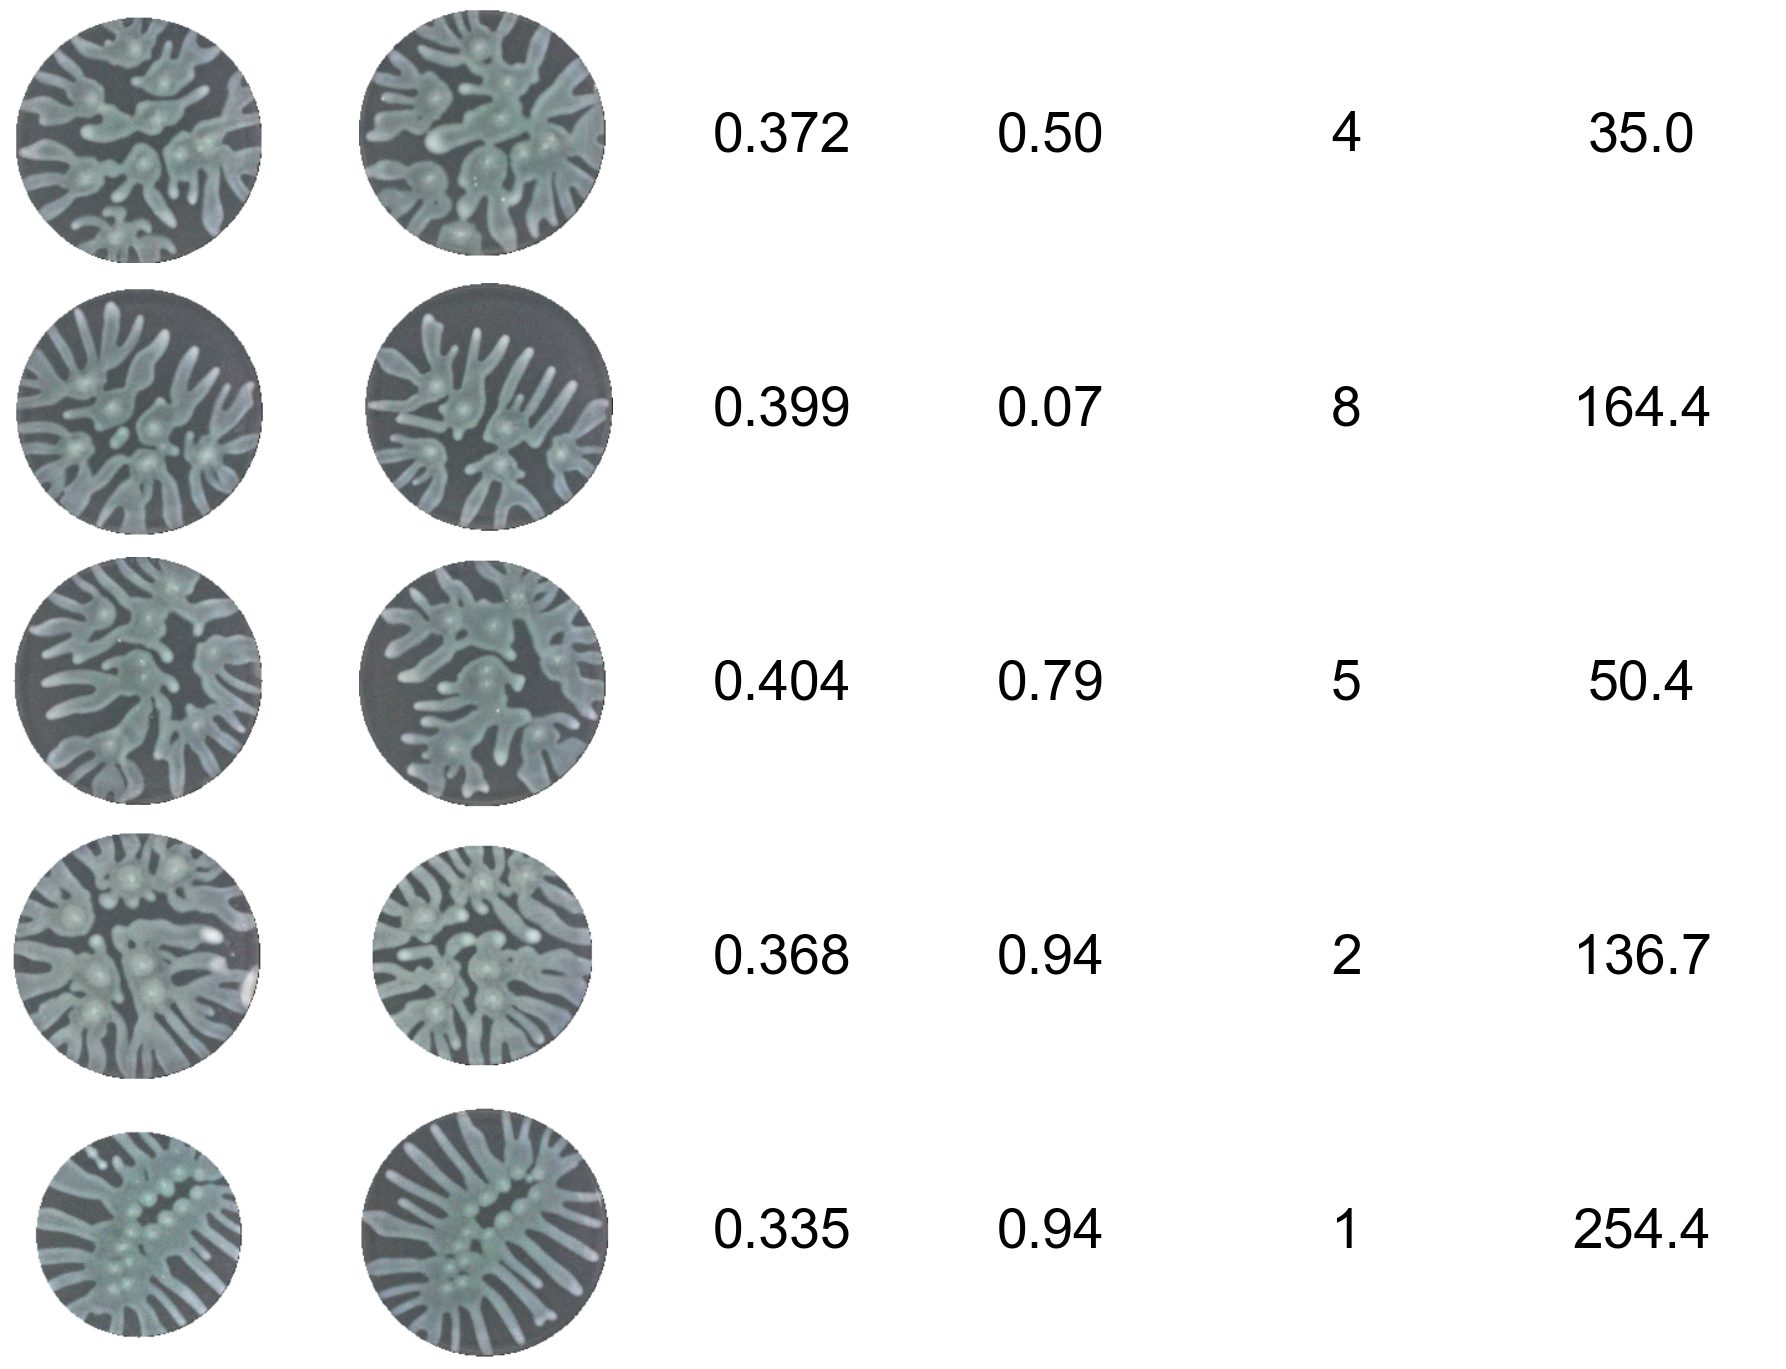

Diffusion panel:


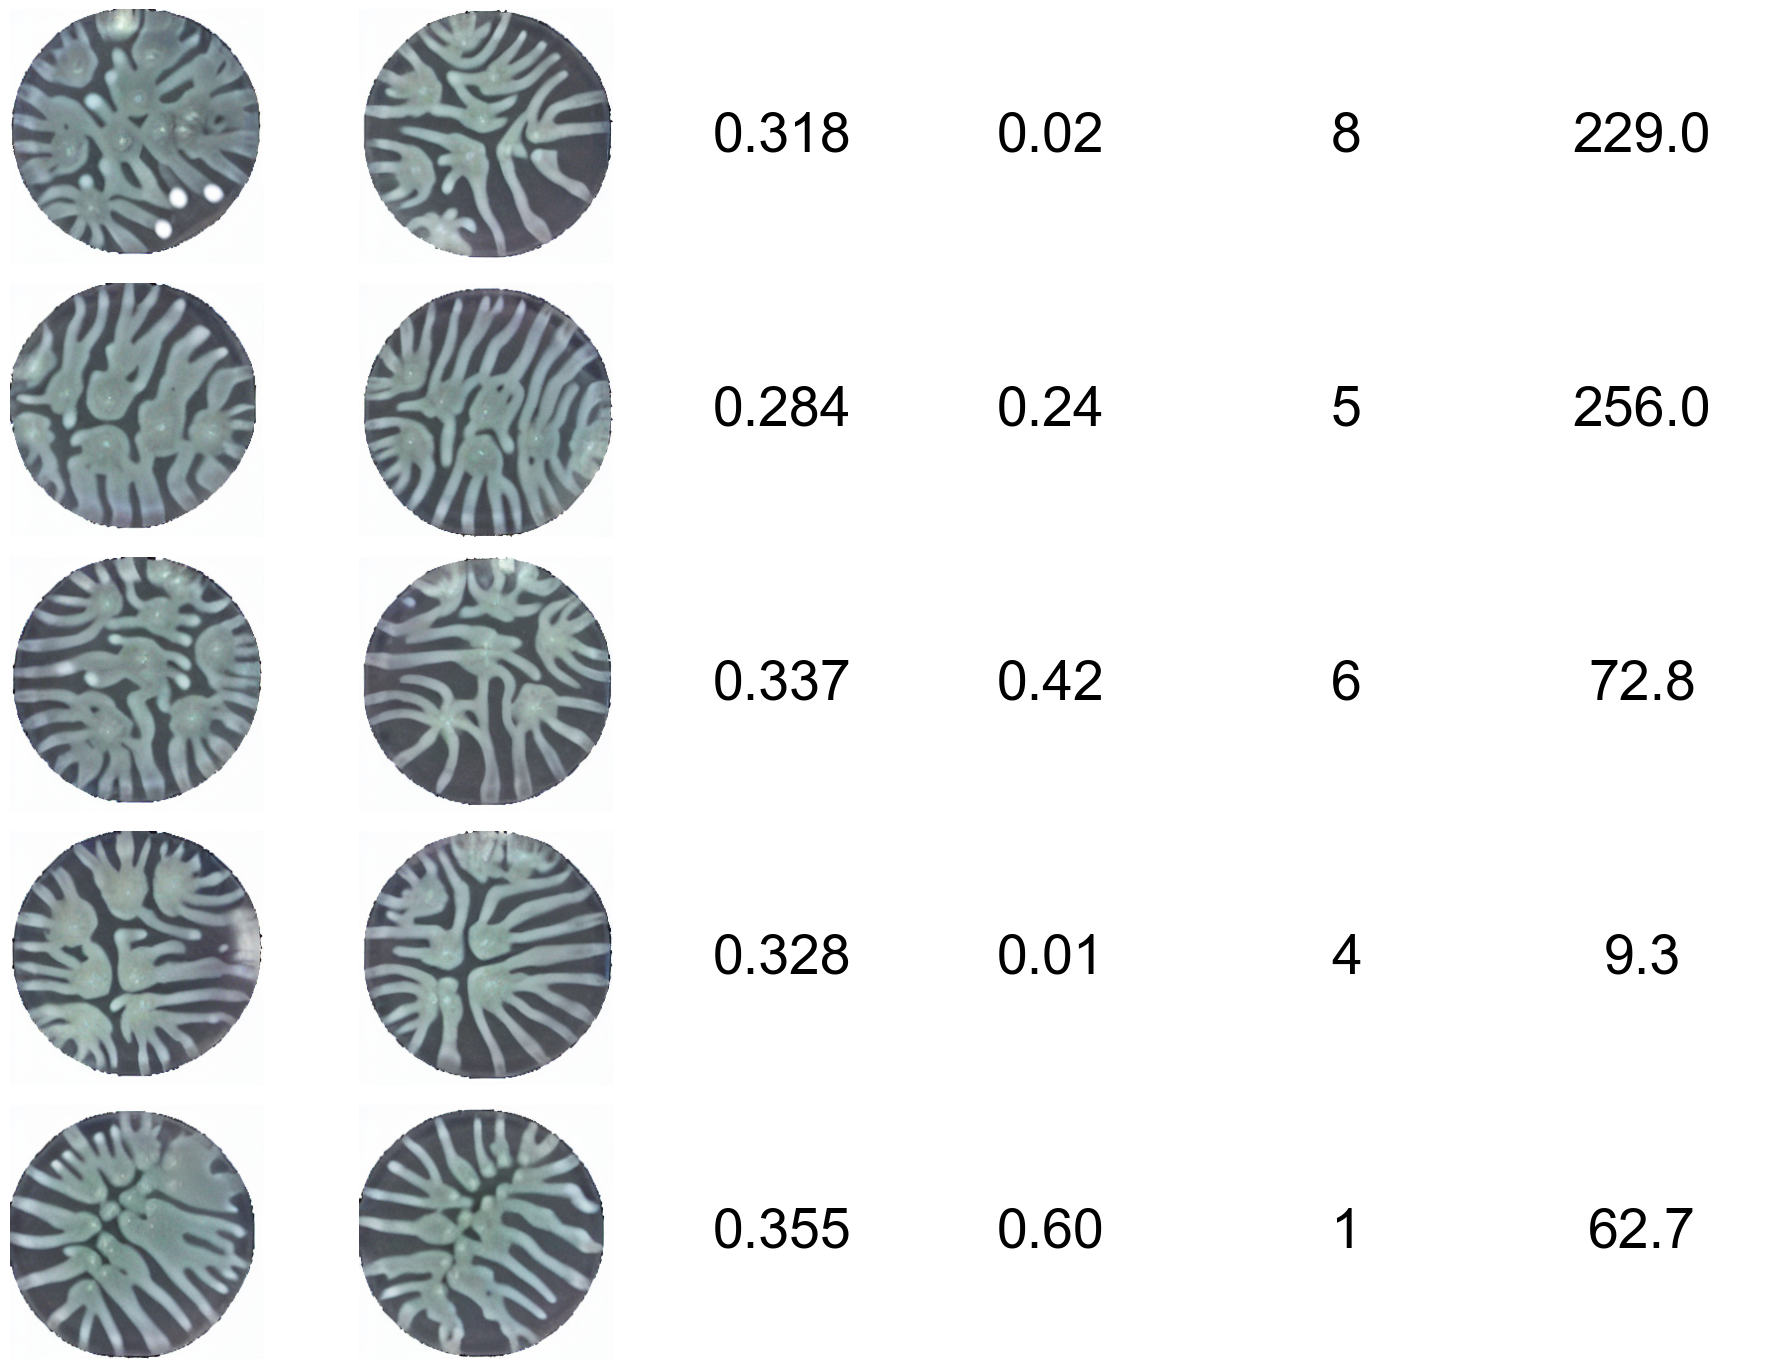

In [5]:
METRIC_COLUMNS = [
    ('ssim', 'SSIM', '.3f'),
    ('absolute_difference_mean_terminal_width_mm', '|Δ mean width|\n(mm)', '.2f'),
    ('absolute_difference_branch_tip_count', '|Δ branch tips|', '.0f'),
    ('absolute_difference_total_skeleton_length_mm', '|Δ skeleton length|\n(mm)', '.1f'),
]


print(f"Length calibration: {MM_PER_PIXEL:.8f} mm/pixel (10 / 25.92), matching the existing variation notebook.")
print("Panel order: Experiment first, Diffusion second.")
print("Columns, left to right:")
print("1: Replicate 1 image.")
print("2: Replicate 2 image (same seeding configuration).")
print("3: Grayscale SSIM between replicates 1 and 2; larger values mean greater image similarity.")
print("4: Absolute difference in plate mean terminal branch width, |mean width 2 - mean width 1| (mm).")
print("   Terminal width is measured 5 path pixels inward from each eligible skeleton tip.")
print("5: Absolute difference in final-skeleton branch-tip counts, |tips 2 - tips 1|.")
print("6: Absolute difference in total Skan skeleton length, |length 2 - length 1| (mm).")
print("Smaller values in columns 4-6 indicate less replicate variation; NA means undefined width.")
print("Rows, top to bottom (same in both panels): " + ", ".join(selected_df.configuration_id))


def plot_replicate_panel(source):
    fig, axes = plt.subplots(SAMPLE_COUNT, 6, figsize=(18, 2.7 * SAMPLE_COUNT),
                             gridspec_kw={'width_ratios': [1.2, 1.2, 0.8, 1, 1, 1]}, squeeze=False)
    metrics = pair_df.loc[pair_df.source == source].set_index('configuration_id')
    for row, config_id in enumerate(selected_df.configuration_id):
        for column, replicate in enumerate([1, 2]):
            axes[row, column].imshow(image_cache[(config_id, source, replicate)]['image'])
        for column, (metric, _, fmt) in enumerate(METRIC_COLUMNS, start=2):
            value = metrics.loc[config_id, metric]
            axes[row, column].text(0.5, 0.5, format(value, fmt) if np.isfinite(value) else 'NA',
                    ha='center', va='center', fontsize=NUMBER_FONTSIZE,
                    transform=axes[row, column].transAxes)
        for ax in axes[row]:
            ax.set_axis_off()
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1, wspace=0.10, hspace=0.08)
    for extension in ['png', 'pdf']:
        fig.savefig(OUTPUT_DIR / f'{source.lower()}_replicate_panel.{extension}', dpi=180, bbox_inches='tight', pad_inches=0)
    print(f'{source} panel:')
    plt.show()
    plt.close(fig)

plot_replicate_panel('Experiment')
plot_replicate_panel('Diffusion')

In [ ]:
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Hybrid PDF export: current Supp. Fig. 16A/B (editable metric values)
from pathlib import Path
import runpy as _pdf_runpy
import matplotlib.pyplot as plt
PDF_PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                        if (p / 'figure_exports').is_dir())
_pdf_helpers = vars(_figure_exports)
_pdf_helpers['save_replicate_panels'](plot_replicate_panel,
    PDF_PROJECT_ROOT / 'sim_to_exp_diffusion' / 'vector based plots')


In [6]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
plate_df.to_csv(_figure_source_path(OUTPUT_DIR / 'replicate_plate_metrics.csv'), index=False)
pair_df.to_csv(_figure_source_path(OUTPUT_DIR / 'replicate_pair_metrics.csv'), index=False)
terminal_df.to_csv(_figure_source_path(OUTPUT_DIR / 'replicate_terminal_widths.csv'), index=False)
metadata = {
    'mm_per_pixel': MM_PER_PIXEL, 'display_length_unit': 'mm',
    'calibration_source': 'morphometric_variation_analysis.ipynb: PIXEL_SIZE = 10/25.92',
    'sample_count': SAMPLE_COUNT, 'random_seed': RANDOM_SEED,
    'include_fixed_test': INCLUDE_FIXED_TEST,
    'selected_configurations': selected_df.configuration_id.tolist(),
    'eligible_configurations': len(eligible_df),
    'skeleton_config': asdict(SKELETON_CONFIG), 'terminal_inset_px': TERMINAL_INSET_PX,
    'experimental_image_preprocessing': 'preprocess_experimental_backgroundwhite',
    'experimental_mask_preprocessing': 'preprocess_experimental_backgroundblack_blackandwhite',
    'ssim': {'grayscale': 'PIL L / 255', 'data_range': 1.0, 'win_size': 7,
             'gaussian_weights': False, 'use_sample_covariance': True},
    'difference': 'absolute replicate 2 minus replicate 1; signed differences also saved',
    'fixed_diffusion_sample_rule': 'Fixed_N_1_1.png vs Fixed_N_1_2.png',
    'python': platform.python_version(),
    'packages': {name: importlib.metadata.version(name) for name in
                 ['numpy', 'pandas', 'scipy', 'scikit-image', 'skan', 'matplotlib', 'Pillow']},
}
(_figure_source_path(OUTPUT_DIR / 'analysis_metadata.json')).write_text(json.dumps(metadata, indent=2) + '\n')
print(f'Saved figures, sampling inventory, per-plate measurements, replicate differences, terminal widths, and metadata to {OUTPUT_DIR}')

Saved figures, sampling inventory, per-plate measurements, replicate differences, terminal widths, and metadata to /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/controlnet_essential/replicate_variation_analysis
